In [1]:
import sys
 
# adding Folder_2 to the system path code/python/tfcat_tools/tfcat_tools
# sys.path.insert(0, 'tfcat_tools/')
sys.path.insert(0, '/obs/kkesri/code/python/tfcat_tools/')
sys.path.insert(0, '/obs/kkesri/code/ephem/')

In [2]:
import numpy 
import numpy.polynomial.polynomial as nppol
import glob
from tqdm import tqdm
from itertools import repeat
from datetime import datetime
from h5py import File
import multiprocessing
import os 
from scipy.io import readsav
from astropy.time import Time

from spacepy import pycdf
from matplotlib import pyplot as plt
import matplotlib.colors as colors
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from mpl_toolkits import axes_grid1
import matplotlib.gridspec as gridspec

from scipy.interpolate import interp1d
from tfcat import TFCat
from tfcat.validate import JSONSCHEMA_URI

#from tfcat_tools.tfcat_tools.edit import merge
#from tfcat_tools.tfcat_tools.mask import Mask
from tfcat_tools.edit import merge
from tfcat_tools.mask import Mask
from tfcat_tools import FeatureCollection

from read_juno_ephemeris_from_amda import *
from jupiter_ephem import *

import pandas as pd
from scipy.stats import skewnorm


In [3]:
def data_to_hdf5(file_name: str,
                time: numpy.ndarray,
                freqs: numpy.ndarray,
                data: numpy.ndarray,):
        """
        Saves the data to disk as a pre-processed HDF5 file.
        """
        output_file = File(file_name, 'w')
        output_file.attrs.create('observer', 'Juno')

        # Has to be done differently as this is an Astropy quantity
        output_file.create_dataset('Time', data=time)
        output_file['Time'].attrs.create('units', 'unix')

        output_file.create_dataset('Frequency', data=freqs)
        output_file['Frequency'].attrs.create('units',  'kHz')

        output_file.create_dataset('Data', data=data)
        output_file['Data'].attrs.create('units',  'W/m2/Hz')


        output_file.close()

def load_hdf5_data(file_name: str):
    """
    Reads a datafile in HDF5 format using the config file set earlier.
    """
    file: File = File(file_name)
    time = file['Time']
    freqs = file['Frequency']
    flux = file['Flux']
    return time, freqs, flux



def nozeros(x):
    return numpy.where(x != 0, x, 1)

def xyz_to_rtp(xyz):
    rtp = numpy.zeros(shape=xyz.shape)
    rtp[..., 0] = numpy.sqrt(xyz[..., 0]**2+xyz[..., 1]**2+xyz[..., 2]**2)
    rtp[..., 1] = numpy.arcsin(xyz[..., 2]/nozeros(rtp[..., 0]))*180/numpy.pi
    rtp[..., 2] = numpy.arctan2(xyz[..., 1], xyz[..., 0])*180/numpy.pi
    return rtp

def set_ephemeris(time, ephemeris, local_time_ephemeris):
    tmin, tmax = time.min(), time.max()
    new_ephemeris_time = ephemeris[0][(ephemeris[0] >= tmin) & (ephemeris[0] <= tmax)]
    new_local_time_ephemeris_time = local_time_ephemeris[0][(local_time_ephemeris[0] >= tmin) & (local_time_ephemeris[0] <= tmax)]
    _ephemeris_xyz = numpy.zeros(shape=(time.shape[0],3))
    _local_time_ephemeris_xyz = numpy.zeros(shape=(time.shape[0],3))
    for i in range(3) :
        _ephemeris = ephemeris[i+1][(ephemeris[0] >= tmin) & (ephemeris[0] <= tmax)]
        _ephemeris_xyz[:, i] = numpy.interp(time, new_ephemeris_time, _ephemeris)
        
        _ephemeris = local_time_ephemeris[i+1][(local_time_ephemeris[0] >= tmin) & (local_time_ephemeris[0] <= tmax)]
        _local_time_ephemeris_xyz[:, i]  = numpy.interp(time, new_local_time_ephemeris_time, _ephemeris)
        
    _ephemeris = numpy.zeros(shape=(time.shape[0],4))
    _ephemeris[:, 0:3] = xyz_to_rtp(_ephemeris_xyz)
    del _ephemeris_xyz
    _local_time_ephemeris = xyz_to_rtp(_local_time_ephemeris_xyz)
    _ephemeris[:, 3] = _local_time_ephemeris[:, 2]
    return _ephemeris

In [4]:

@numpy.vectorize
def webgeocalc_date_to_datetime(date_YMD,date_hours):
    return datetime.datetime.strptime(date_YMD+"T"+date_hours,"%Y-%m-%dT%H:%M:%S.%f")

@numpy.vectorize
def unix_date_to_datetime(date_unix):
    return datetime.datetime.fromtimestamp(date_unix)


def juno_ephemeris_from_webgeocalc(file, planetary_radius=False):
    if planetary_radius == False:
        print("### User needs to give a planetary radius to have ephemeris in planetary units ###")
    data_file = numpy.loadtxt(file,dtype="str")
    date = webgeocalc_date_to_datetime(data_file[:,0],data_file[:,1])
    x_coord = data_file[:,5].astype(float)
    y_coord = data_file[:,6].astype(float)
    z_coord = data_file[:,7].astype(float)

    return (date,x_coord[:]/planetary_radius,y_coord[:]/planetary_radius,z_coord[:]/planetary_radius)


In [5]:
# Function to read and concatenate variables from HDF5 files
def concatenate_hdf5_files(file_list, variable_names, path_files = './'):
    concatenated_data = {var: [] for var in variable_names}

    for file in file_list:
        with File(path_files+file, 'r') as f:
            for var in variable_names:
                concatenated_data[var].append(f[var][:])

    # Concatenate lists into numpy arrays
    concatenated_data = {var:numpy.concatenate(concatenated_data[var], axis=0) for var in variable_names}

    return concatenated_data


In [6]:
# Function to recursively flatten the nested structure
def flatten(nested_list):
    flat_list = []
    for item in nested_list:
        if isinstance(item, list):
            flat_list.extend(flatten(item))
        else:
            flat_list.append(item)
    return flat_list

In [7]:
def sort_cat(cat: TFCat):
    crs = cat.crs
    properties = cat.properties
    fields= cat.data.fields
    schema = cat.data["$schema"]
    event = FeatureCollection(cat.data, properties=properties, fields=fields, crs=crs, schema=schema).as_table()
    event.sort(['tmin'])
    return TFCat(FeatureCollection().from_table(table=event, properties=properties, fields=fields, crs=crs, schema=schema))



In [8]:
def load_intensity_from_hdf5_file(file_name: str):
    """
    Reads a datafile in HDF5 format using the config file set earlier.
    """
    file: File = File(file_name)
    normalized_intensity_bKOM = numpy.array(file['normalized_intensity_bKOM'])

    return normalized_intensity_bKOM       

In [9]:
from spacepy import pycdf
def load_background_data(cdf_file_path):
    with pycdf.CDF(cdf_file_path) as cdf_file:
        background = numpy.array(cdf_file["Background"])
        sigma = numpy.array(cdf_file["Sigma"])
        frequency = numpy.array(cdf_file["Frequency"])
        
        #for attr in cdf_file["Background"].attrs:        
        #    print(f"{attr}: {cdf_file['Background'].attrs[attr]}")
    
    return background, sigma, frequency


In [10]:
#thresholding data
def thresholding_data(data,background):

    occurrence = numpy.zeros(data.shape)
    for ifreq in range(len(background)):
        mask = data[:, ifreq] > background[ifreq]
        occurrence[mask, ifreq] = 1
    return occurrence

In [11]:
@numpy.vectorize
def from_UTC_to_astropy_Time(time_UTC):
    return Time(time_UTC[:-4]).unix

In [12]:
from webgeocalc import Calculation

def get_ephem_from_wgc(observer, time, api = None):
    """
    Get ephemeris data from WGC servers through API
    :param observer:
    :type observer: dict
    :param time:
    :type time: dict
    :return:
    :rtype: dict
    """

    wgc_kernels = [
                    "pds/wgc/mk/ground_stations_v0018.tm",
                    "pds/wgc/mk/solar_system_v0056.tm",
                    "pds/wgc/mk/latest_lsk_v0004.tm",
                    ]

    time_interval = [time['time_start'].strftime("%Y-%m-%d %H:%M:%S"), time['time_end'].strftime("%Y-%m-%d %H:%M:%S")]                    

    if api == None:
        api = ''
    elif api.lower() == 'obspm':
        api = 'https://voparis-webgeocalc2.obspm.fr/geocalc/api'
        #api = "https://wgc.jpl.nasa.gov:8443/webgeocalc/api"
        #api = 'https://wgc.obspm.fr/webgeocalc/api'
    calc = Calculation(
        api = api,
        kernel_paths =  wgc_kernels,
        intervals = time_interval,
        time_step = time['time_step'],
        time_step_units = time['time_units'],
        calculation_type = 'STATE_VECTOR',
        target = observer['NAME'],
        observer = observer['PARENT'],
        reference_frame = observer['referenceFrame'],
        aberration_correction = 'NONE',
        state_representation = 'PLANETOGRAPHIC',
    )

    calc.payload
    calc.run()

    longitude = numpy.array(calc.results['LONGITUDE'])  # must be in LongW for ExPRES
    latitude = numpy.array(calc.results['LATITUDE'])
    distance = numpy.array(calc.results['ALTITUDE'])
    time_ephem = numpy.array(calc.results['DATE'])

    result_data = {
                    'time': time_ephem,
                    'longitude': -longitude, # So that the longitude is counting West (SIII for Jupiter)
                    'latitude': latitude,
                    'distance': distance,

                }
    return result_data
    

Path to data, catalogue and ephemeris files

In [13]:
#PATHS
year = [2016,2017,2018,2019,2020,2021]
#year = [2020,2021]
path_cat = {f'{iyear}': f'/obs/kkesri/code/data/TFCat_catalog_2.1/juno_waves_lira_tfcat_{iyear}.json' for iyear in year}
path_dir_data  = '/obs/juno_data_preprocessed/'
path_dir_ephem = '/obs/kkesri/code/ephem/'
data_path_IAU_ephemeris = f"{path_dir_ephem}juno_jup_xyz_iau_2016_2025.txt"
data_path_JSO_ephemeris = f"{path_dir_ephem}juno_jup_xyz_jso_2016_2025.txt"

Definition of output path and keywords

In [14]:
directory_path_out = 'outputs/'
savefig = True

Constants Definition

In [15]:
AU = 149597870.700 # 1 astronomical unit in km
RJ = 71492. # Jovian radius in km

Loading Ephemeris

In [16]:
all_ephemeris = juno_ephemeris_from_amda(data_path_IAU_ephemeris)
local_time_ephemeris = juno_ephemeris_from_amda(data_path_JSO_ephemeris)

#print(threshold)

Time range definition

In [17]:
time_start = datetime.datetime(2016,6,1)
time_end = datetime.datetime(2021, 3, 1, 0, 0, 0) # or After datetime.datetime(2021, 9, 1, 0, 0, 0). Gap inbetween

Dates for Louis et al. 2021

In [ ]:
time_start = datetime.datetime.strptime("2016100","%Y%j")
time_end = datetime.datetime.strptime("2019172", "%Y%j")

HDF5 data files reading

In [18]:
hdf5_files_2016 = ["jno_wav_cdr_lesia_2016_apr_aug.preprocessed.hdf5",
"jno_wav_cdr_lesia_2016_sep_dec.preprocessed.hdf5"]
hdf5_files_2017 = ["jno_wav_cdr_lesia_2017_jan_apr.preprocessed.hdf5",
"jno_wav_cdr_lesia_2017_may_aug.preprocessed.hdf5",
"jno_wav_cdr_lesia_2017_sep_dec.preprocessed.hdf5"]
hdf5_files_2018 = ["jno_wav_cdr_lesia_2018_jan_apr.preprocessed.hdf5",
"jno_wav_cdr_lesia_2018_may_aug.preprocessed.hdf5",
"jno_wav_cdr_lesia_2018_sep_dec.preprocessed.hdf5"]
hdf5_files_2019 = ["jno_wav_cdr_lesia_2019_jan_apr.preprocessed.hdf5",
"jno_wav_cdr_lesia_2019_may_aug.preprocessed.hdf5",
"jno_wav_cdr_lesia_2019_sep_dec.preprocessed.hdf5"]
hdf5_files_2020 = ["jno_wav_cdr_lesia_2020_jan_apr.preprocessed.hdf5",
"jno_wav_cdr_lesia_2020_may_aug.preprocessed.hdf5",
"jno_wav_cdr_lesia_2020_sep_dec.preprocessed.hdf5"]
hdf5_files_2021 = ["jno_wav_cdr_lesia_2021_jan_apr.preprocessed.hdf5",
"jno_wav_cdr_lesia_2021_may_aug.preprocessed.hdf5",
"jno_wav_cdr_lesia_2021_sep_dec.preprocessed.hdf5"]

# /!\ be careful, do not take into account beg. of 2021. bKOM is inverse mask, so if catalogue not done, mask takes everything
# /!\ do not take data at PJ, so wh en d < 2 R_Jupiter

# Dictionary to hold file lists for each year
files_dict = {
    2016: hdf5_files_2016,
    2017: hdf5_files_2017,
    2018: hdf5_files_2018,
    2019: hdf5_files_2019,
    2020: hdf5_files_2020,
    2021: hdf5_files_2021,
}


# Variables to concatenate
variables = ['Flux', 'Time']

# Dictionary to store concatenated data for each year
yearly_data = {}

# Process each year
for iyear, files in files_dict.items():
    yearly_data[iyear] = concatenate_hdf5_files(files, variables, path_files = path_dir_data)


Frequency reading

In [19]:
with File(path_dir_data+hdf5_files_2016[0]) as hdf_file:
    Frequency = numpy.array(hdf_file['Frequency'])

Data variables and TFCat catalogues sorting and creation of dictionnaries

In [20]:
file_name_hdf5 = {f'{iyear}': f'mask_{iyear}.hdf5' for iyear in year}
cat = {f'{iyear}': sort_cat(TFCat.from_file(path_cat[f'{iyear}'])) for iyear in year}
for iyear in year:
    cat[f'{iyear}'].properties['instrument_name'] = "Waves_" 

time = {f'{iyear}': numpy.array(Time(yearly_data[iyear]['Time'], format="jd").unix) for iyear in year}
data = {f'{iyear}': numpy.array(yearly_data[iyear]['Flux']) for iyear in year}

Selection in time

In [21]:
mask_time_start = time[time_start.strftime("%Y")] >= Time(time_start,format="datetime").unix
time[time_start.strftime("%Y")] = time[time_start.strftime("%Y")][mask_time_start]
data[time_start.strftime("%Y")] = data[time_start.strftime("%Y")][mask_time_start,:]

In [22]:
mask_time_end = time[time_end.strftime("%Y")] <= Time(time_end,format="datetime").unix
time[time_end.strftime("%Y")] = time[time_end.strftime("%Y")][mask_time_end]
data[time_end.strftime("%Y")] = data[time_end.strftime("%Y")][mask_time_end,:]

Ephemerides calculation only on the wanted time range

In [23]:
time_arrays = list(time.values())
time_over_year_sec = numpy.concatenate(time_arrays)
# Normalization at 1 AU
mask_time = (all_ephemeris[0]>= time_start) & (all_ephemeris[0]< time_end)
ephem_x = all_ephemeris[1][mask_time]
ephem_y = all_ephemeris[2][mask_time]
ephem_z = all_ephemeris[3][mask_time]
ephem_date = all_ephemeris[0][mask_time]

distance = numpy.sqrt(ephem_x**2 + ephem_y**2 + ephem_z**2)
lat = (numpy.pi-numpy.arccos(ephem_z / distance)) * 180/numpy.pi
lon = numpy.pi-numpy.arctan2(ephem_y,ephem_x) * 180/numpy.pi

distance = numpy.sqrt(ephem_x**2 + ephem_y**2 + ephem_z**2)
lat = 90 - (numpy.arccos(ephem_z / distance))*180/numpy.pi 
lon = (360 - ((numpy.arctan2(ephem_y,ephem_x))*180/numpy.pi)) % 360



time_ephem_sec = Time(ephem_date, format='datetime').unix
oblon=numpy.interp(time_over_year_sec,time_ephem_sec,lon)
oblat=numpy.interp(time_over_year_sec,time_ephem_sec,lat) 
obdist=numpy.interp(time_over_year_sec,time_ephem_sec,distance)
obmlat=10.31*numpy.cos((196.61-oblon)*numpy.pi/180.)+oblat

In [24]:
print(Time(time_over_year_sec[0], format = "unix").isot, Time(time_over_year_sec[-1], format = "unix").isot,
        Time(time_ephem_sec[0], format = "unix").isot, Time(time_ephem_sec[-1], format = "unix").isot)

2016-06-01T00:00:08.184 2021-02-28T23:59:09.184 2016-06-01T00:05:00.000 2021-02-28T23:55:00.000


Frequency range selection

In [25]:
#time_index = numpy.where((time.datetime >= time_start) & (time.datetime < time_end))[0]

index_freq_LFR = numpy.where((Frequency > 1) & (Frequency < 142))[0][0:-1]
index_freq_bKOM = numpy.where((Frequency > 10) & (Frequency < 142))[0][0:-1]
index_freq_DAM = numpy.where(Frequency >3000)[0]

Calculating or loading normalized_intensity_bKOM

In [26]:
calculate_intensity = False
if calculate_intensity:
    intensity_bKOM_list = []

    for index, iyear in enumerate(year):
        print(f"{iyear}")
        mask_juno_bKOM = Mask(
                            cat[f'{iyear}'],
                            time[f'{iyear}'],
                            Frequency[index_freq_bKOM],
                            data[f'{iyear}'][:,index_freq_bKOM]
                            )

        mask_juno_bKOM_data =  mask_juno_bKOM.apply('QP','nLF','nKOM','QP?','nLF?','nKOM?','anom',invert=True)
        mask_juno_bKOM_data = mask_juno_bKOM_data * 377
        #integrated_intensity_bKOM = numpy.sum(mask_juno_bKOM_data, axis=1)

        intensity_bKOM_list.append(mask_juno_bKOM_data)

        #if index == 0:
        #    integrated_intensity_bKOM_over_year = integrated_intensity_bKOM
        #else:
        #    integrated_intensity_bKOM_over_year = [integrated_intensity_bKOM_over_year, integrated_intensity_bKOM]
    intensity_bKOM_over_year = numpy.concatenate(intensity_bKOM_list)

    #integrated_intensity_bKOM_over_year_flattened_arrays = flatten(integrated_intensity_bKOM_over_year)
    #normalized_integrated_intensity_bKOM = numpy.concatenate(integrated_intensity_bKOM_over_year_flattened_arrays)*(obdist/AU)**2
    normalized_intensity_bKOM = intensity_bKOM_over_year * (obdist[:, numpy.newaxis]*RJ / AU)**2    

    output_file = File('normalized_intensity_bKOM.hdf5', 'w')
    output_file.attrs.create('observer', 'Juno')
    output_file.create_dataset('normalized_intensity_bKOM', data=normalized_intensity_bKOM)
    output_file['normalized_intensity_bKOM'].attrs.create('units', 'W/m2/Hz@1AU')
    output_file.close()
else:
    normalized_intensity_bKOM = load_intensity_from_hdf5_file("/obs/kkesri/code/data/normalized_intensity_bKOM_catalog_v20.hdf5")


Filtering with distance

In [27]:
mask_distance = obdist < 10
normalized_intensity_bKOM[mask_distance,:] = numpy.nan

Loading background data

In [28]:
cdf_file_path = "/Users/clouis/Documents/Data/Juno/Waves/2021/12/jno_wav_cdr_lesia_20211201_v02.cdf"
background, sigma_background, frequency_background = load_background_data(cdf_file_path)
# selection in frequency and /377 for V^2/m^2/Hz --> W/m^2/Hz
background = background[index_freq_bKOM]/377
sigma_background = sigma_background[index_freq_bKOM]

CDFError: NO_SUCH_CDF: The specified CDF does not exist.

Calculating background from normalized_intensity_bKOM data

In [28]:
background_from_data = numpy.zeros(normalized_intensity_bKOM.shape[1])
for ifreq in range(normalized_intensity_bKOM.shape[1]):
    mask = normalized_intensity_bKOM[:,ifreq] > 0
    background_from_data[ifreq] =  numpy.nanmean(normalized_intensity_bKOM[mask, ifreq])
    

Calculating integrated intensity over frequency

In [ ]:
normalized_integrated_intensity_bKOM = numpy.sum(normalized_intensity_bKOM, axis=1)

Calculating integrated occurrence over frequency using background data

In [30]:
occurrence = thresholding_data(normalized_intensity_bKOM, background_from_data)
integrated_occurrence = numpy.sum(occurrence, axis = 1)
mask = integrated_occurrence > 0
integrated_occurrence[mask] = 1

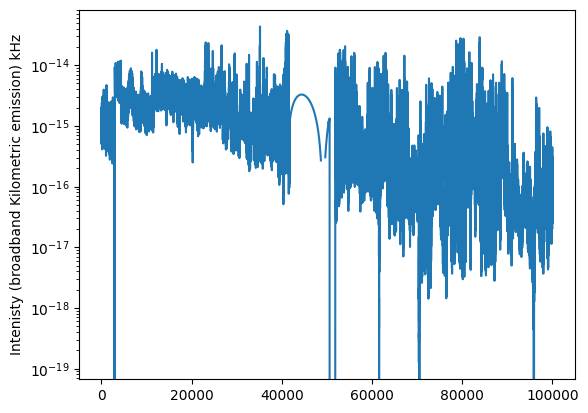

In [31]:
plt.plot(normalized_integrated_intensity_bKOM[0:100000])
plt.ylabel('Intenisty (broadband Kilometric emission) kHz')
plt.yscale('log')
plt.show()

## Incorporating Matt's data and Juno's Data together

In [32]:
time_datetime = pd.to_datetime(time_over_year_sec, unit='s')

Resampling the Juno data to change the resolution from 1 min to 1 hour (roughly)

case = 0: When you want all the arrays sliced according to the timestamps of your choosing

case = 1: When you just the entire resampled/original data


In [33]:
def resample_hourly(start, end, case): 
    df_juno = pd.DataFrame({ 
        "time": pd.to_datetime(time_over_year_sec, unit='s'), 
        "intensity": normalized_integrated_intensity_bKOM 
        }) 
    
    df_juno.set_index("time", inplace=True) 
    df_hourly = df_juno.resample("1H").mean() 
    
    df_dist = pd.DataFrame({ 
        "time": pd.to_datetime(time_over_year_sec, unit='s'), 
        "dist": obdist 
        }) 
    
    df_dist.set_index("time", inplace=True) 
    df_dist_hourly = df_dist.resample("1H").mean() 
    df_combined = df_hourly.join(df_dist_hourly) 
    df_subset = df_combined.loc[start:end] 
    
    time_subset = df_subset.index 
    intensity_subset = df_subset["intensity"] 
    dist_subset = df_subset["dist"] 
    
    if case == 0:  # Gives back only the sliced data
        return time_subset, intensity_subset, dist_subset
    
    if case == 1:  # Gives back the entire dataset
        return df_hourly
    

def sample_minute(start, end, case):
    if case == 0:  # Gives back the sliced data
        mask = (time_datetime >= start) & (time_datetime <= end)

        time_subset = time_datetime[mask]
        intensity_subset = normalized_integrated_intensity_bKOM[mask]
        dist_subset = numpy.array(obdist)[mask]
        
        return time_subset, intensity_subset, dist_subset
    
    if case == 1:  # Gives back the entire dataset
        time = time_datetime
        intensity = normalized_integrated_intensity_bKOM
        dist = numpy.array(obdist)

        return time, intensity, dist

Choosing to mark only a few equally spaced date, time and position coordinates in the entire interval 

In [34]:
def ticks(time_subset, dist_subset):
    n_ticks = 8
    indices = numpy.linspace(0, len(time_subset)-1, n_ticks, dtype=int)

    tick_times = time_subset[indices]
    tick_labels = [
        f"{t.strftime('%Y-%m-%d')}\n{d:.2f} Rj"
        for t, d in zip(tick_times, dist_subset[indices])
    ]
    return tick_times, tick_labels

Reading Matt's File

In [35]:
def readMMESH_fromFile(fullfilename):
    """
    Parameters
    ----------
    fullfilename : string
        The fully qualified (i.e., absolute) filename pointing to the MMESH 
        output .csv file

    Returns
    -------
    mmesh_results : pandas DataFrame
        The results of the MMESH run
    """
    
    #   Read the csv, parsing MultiIndex columns correctly
    mmesh_results = pd.read_csv(fullfilename, 
                                comment='#', header=[0,1], index_col=[0])
    
    #   Reset the index to be datetimes, rather than integers
    mmesh_results.index = pd.to_datetime(mmesh_results.index)
    
    return mmesh_results

output = readMMESH_fromFile("/obs/kkesri/code/data/MMESH_data/MMESH_JupiterMME.csv")
df=pd.DataFrame(output)

Slicing the data columns according to our interval of interest, for Matt's data

In [36]:
def MMESH_slicing(start, end, diag: str):
    diag_available = ['B_mag','B_mag_a', 'B_mag_loc', 'B_mag_scale', 
                      'n_tot','n_tot_a', 'n_tot_loc', 'n_tot_scale',
                      'P_dyn','P_dyn_a', 'P_dyn_loc', 'P_dyn_scale',
                      'u_mag','u_mag_a', 'u_mag_loc', 'u_mag_scale']
    
    if diag not in diag_available:
        return df.loc[start:end]
        #raise ValueError(f"{diag} not found")
    
    i = diag_available.index(diag)
    return df.loc[start:end, df.columns[i]]

Function defined to higlight a certain stripped area in the timeseries which has to be either excluded or included. 

If you want to show excluded or deleted data: choose case = 0

If you want to show special or inclusive data: choose case = 1

In [37]:
def highlighted_regions(parameter, quantity, case, time):
    if case == 0:
        mask_excluded = quantity < parameter
    if case == 1:
        mask_excluded = quantity > parameter
    
    excluded_regions = []
    in_region = False
    region_start = None  

    for i in range(len(mask_excluded)):
        if mask_excluded[i] and not in_region:
            region_start = time[i]  
            in_region = True
        elif not mask_excluded[i] and in_region:
            region_end = time[i]    
            excluded_regions.append((region_start, region_end))
            in_region = False

    if in_region:
        excluded_regions.append((region_start, time[-1]))

    return excluded_regions

# Interaction of Solar wind and Jovian magnetosphere

(A) Data representation

In [38]:
# =============================================================================
# PART A — LOAD, CLEAN, RESAMPLE, AND VISUALIZE RAW DATA
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# A.0 Analysis interval
# -----------------------------------------------------------------------------

start = pd.Timestamp("2016-06-01 00:00:00")
end   = pd.Timestamp("2021-02-27 22:00:00")

In [61]:
# -----------------------------------------------------------------------------
# A.1 Build Juno bKOM + distance dataframe
# -----------------------------------------------------------------------------

df_juno_min = pd.DataFrame({
    "time": pd.to_datetime(time_over_year_sec, unit="s"),
    "intensity_raw": normalized_integrated_intensity_bKOM,
    "dist_RJ": obdist
})

df_juno_min = df_juno_min.set_index("time").sort_index()

# Replace non-physical intensity values with NaN
df_juno_min["intensity"] = df_juno_min["intensity_raw"].where(
    df_juno_min["intensity_raw"] > 0,
    np.nan
)

# Optional: interpolate only small gaps
# This avoids inventing long missing intervals.
df_juno_min["intensity_interp"] = (df_juno_min["intensity"].interpolate(method="time", limit=1))

# Distance should be smooth, but keep separately
df_juno_min["dist_interp"] = (
    df_juno_min["dist_RJ"]
    .interpolate(method="time")
)

# Slice minute-level data
df_juno_min_subset = df_juno_min.loc[start:end].copy()

# -----------------------------------------------------------------------------
# A.2 Hourly resampling
# -----------------------------------------------------------------------------

df_hourly = pd.DataFrame()

df_hourly["intensity"] = (
    df_juno_min["intensity_interp"]
    .resample("1H")
    .mean()
)

df_hourly["dist"] = (
    df_juno_min["dist_interp"]
    .resample("1H")
    .mean()
)

df_hourly1 = df_hourly.loc[start:end].copy()

# -----------------------------------------------------------------------------
# A.3 Data-quality checks
# -----------------------------------------------------------------------------

raw_subset = df_juno_min.loc[start:end, "intensity_raw"]
clean_subset = df_juno_min.loc[start:end, "intensity"]
interp_subset = df_juno_min.loc[start:end, "intensity_interp"]

n_total = len(raw_subset)
n_zero = (raw_subset == 0).sum()
n_negative = (raw_subset < 0).sum()
n_nan_clean = clean_subset.isna().sum()
n_nan_interp = interp_subset.isna().sum()

print("\n--- Juno bKOM quality check ---")
print(f"Total minute samples      : {n_total}")
print(f"Zero samples              : {n_zero}")
print(f"Negative samples          : {n_negative}")
print(f"NaN after zero removal    : {n_nan_clean}")
print(f"NaN after interpolation   : {n_nan_interp}")
print(f"Zero fraction             : {100*n_zero/n_total:.2f}%")



--- Juno bKOM quality check ---
Total minute samples      : 2622120
Zero samples              : 6709
Negative samples          : 0
NaN after zero removal    : 40557
NaN after interpolation   : 40414
Zero fraction             : 0.26%


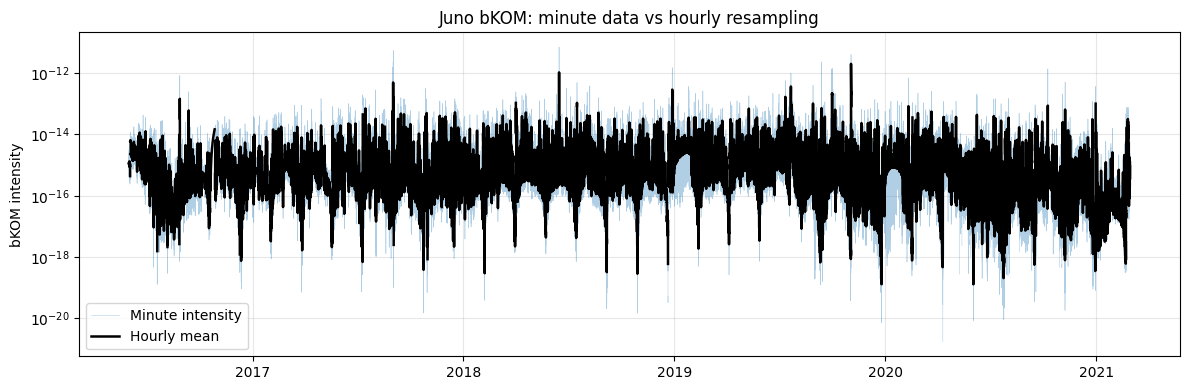

In [62]:
# -----------------------------------------------------------------------------
# A.4 Resampling sanity plot
# -----------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(df_juno_min_subset.index, df_juno_min_subset["intensity"], lw=0.4, alpha=0.35, label="Minute intensity")
ax.plot(df_hourly1.index, df_hourly1["intensity"], lw=1.8, color="black", label="Hourly mean")

ax.set_yscale("log")
ax.set_ylabel("bKOM intensity")
ax.set_title("Juno bKOM: minute data vs hourly resampling")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
# -----------------------------------------------------------------------------
# A.5 MMESH variables
# -----------------------------------------------------------------------------

P_dyn = MMESH_slicing(start, end, "P_dyn")
B_mag = MMESH_slicing(start, end, "B_mag")
u_mag = MMESH_slicing(start, end, "u_mag")
n_tot = MMESH_slicing(start, end, "n_tot")

timestamps = MMESH_slicing(start, end, "1").index

print("\n--- MMESH cadence check ---")
print(P_dyn.index.to_series().diff().value_counts().head())

print("\nMMESH ranges:")
print("P_dyn:", P_dyn.min(), P_dyn.max())
print("B_mag:", B_mag.min(), B_mag.max())
print("u_mag:", u_mag.min(), u_mag.max())
print("n_tot:", n_tot.min(), n_tot.max())

# -----------------------------------------------------------------------------
# A.6 Alignment check
# -----------------------------------------------------------------------------

df_align_check = pd.concat(
    [
        df_hourly1["intensity"],
        P_dyn.rename("P_dyn"),
        B_mag.rename("B_mag"),
        u_mag.rename("u_mag"),
        n_tot.rename("n_tot")
    ],
    axis=1
)

print("\n--- Alignment check ---")
print(df_align_check.shape)


--- MMESH cadence check ---
datetime
0 days 01:00:00    41590
Name: count, dtype: int64

MMESH ranges:
P_dyn: 0.0026 0.9559
B_mag: 0.0271 3.5893
u_mag: 307.7363 590.3313
n_tot: 0.0073 2.9196

--- Alignment check ---
(41591, 5)


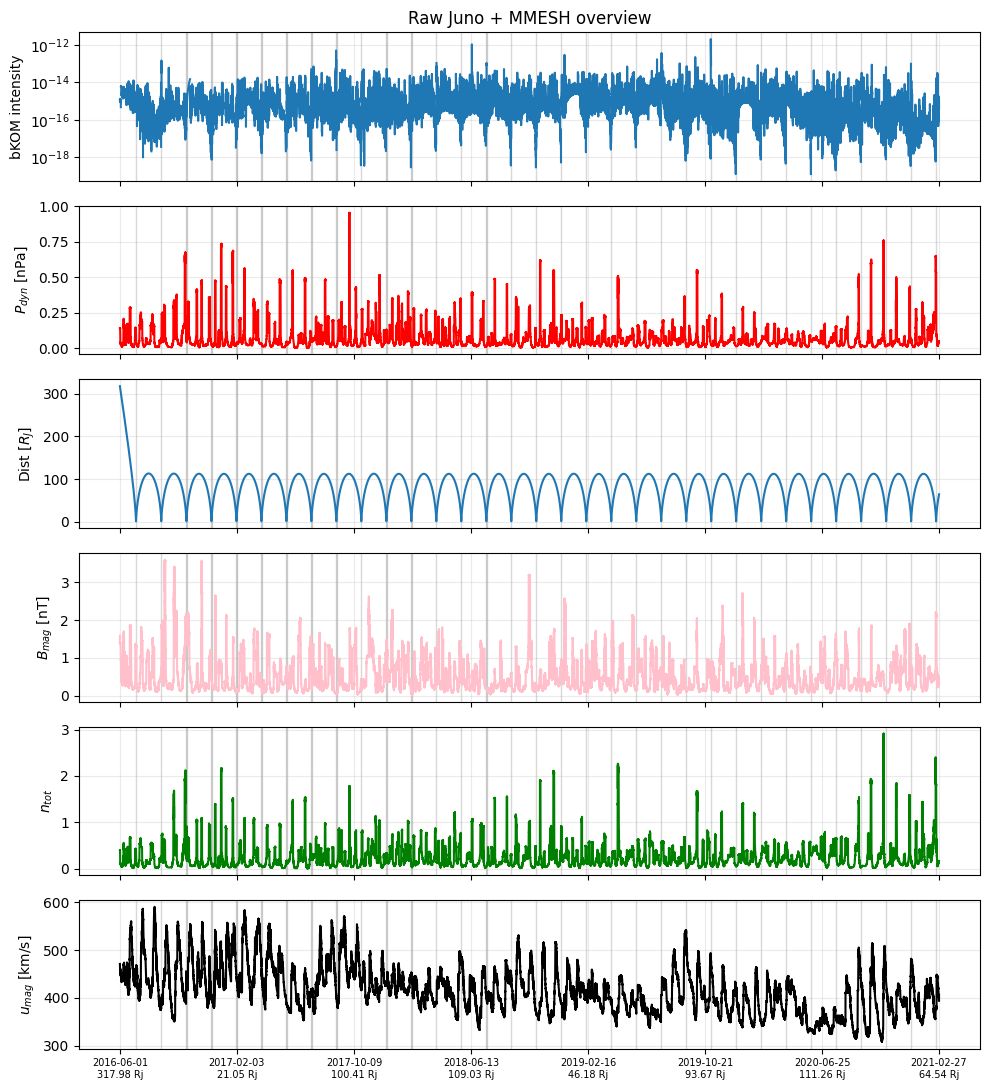

In [46]:
# -----------------------------------------------------------------------------
# A.7 Raw overview plot
# -----------------------------------------------------------------------------

time_subset = df_hourly1.index
intensity_subset = df_hourly1["intensity"]
dist_subset = df_hourly1["dist"]

x_marker = ticks(time_subset, dist_subset)

fig, axs = plt.subplots(6, 1, sharex=True,figsize=(10, 11))

# bKOM
axs[0].plot(time_subset, intensity_subset, color="tab:blue")
axs[0].set_yscale("log")
axs[0].set_ylabel("bKOM intensity")
axs[0].set_title("Raw Juno + MMESH overview")

# P_dyn
axs[1].plot(P_dyn.index, P_dyn, color="red")
axs[1].set_ylabel(r"$P_{dyn}$ [nPa]")
#axs[1].set_yscale("log")

# distance
axs[2].plot(time_subset, dist_subset, color="tab:blue")
axs[2].set_ylabel(r"Dist [$R_J$]")

# B_mag
axs[3].plot(B_mag.index, B_mag, color="pink")
axs[3].set_ylabel(r"$B_{mag}$ [nT]")

# n_tot
axs[4].plot(n_tot.index, n_tot, color="green")
axs[4].set_ylabel(r"$n_{tot}$")

# u_mag
axs[5].plot(u_mag.index, u_mag, color="black")
axs[5].set_ylabel(r"$u_{mag}$ [km/s]")

# Exclude close Juno regions
excluded_regions = highlighted_regions(10, dist_subset.values, 0, time_subset)

for ax in axs:
    for region_start, region_end in excluded_regions:
        ax.axvspan(region_start, region_end, color="grey", alpha=0.3)

    ax.grid(alpha=0.25)

plt.xticks(x_marker[0], x_marker[1], size=7, rotation=0)
plt.tight_layout()
plt.show()

(B) Declaring the Variables and including the Jupiter-sun-earth angles

In [47]:
# =============================================================================
# PART B — PARAMETERS + JSE ANGLE LOADING
# =============================================================================

# -----------------------------------------------------------------------------
# B.0 Parameters
# -----------------------------------------------------------------------------

# P_dyn event detection
SMOOTH_P = 3
PLATEAU_FRACTION = 0.9
MIN_EVENT_DURATION = 3

# bKOM response search
BKOM_SEARCH_WINDOW = 36       # ± hours around P_dyn event midpoint

# JSE reliability / geometry
JSE_VALID_RANGE = (-180, 180)

# -----------------------------------------------------------------------------
# B.1 Load JSE angle file
# -----------------------------------------------------------------------------

path_jse = "/obs/kkesri/code/data/output-jup_sw_da_2016.txt"

df_jse = pd.read_csv(
    path_jse,
    comment="#",
    sep=r"\s+",
    names=["time", "angle"]
)

df_jse["time"] = pd.to_datetime(df_jse["time"])
df_jse = df_jse.set_index("time").sort_index()

# -----------------------------------------------------------------------------
# B.2 Clean JSE angle
# -----------------------------------------------------------------------------

df_jse["angle"] = df_jse["angle"].where(
    df_jse["angle"].between(*JSE_VALID_RANGE),
    np.nan
)

df_jse["angle"] = df_jse["angle"].interpolate(method="time")

df_jse_subset = df_jse.loc[start:end].copy()

print("\n--- JSE angle check ---")
print(df_jse_subset.head())
print(df_jse_subset.tail())
print(df_jse_subset["angle"].describe())


--- JSE angle check ---
                      angle
time                       
2016-06-01 00:00:00  63.332
2016-06-01 01:00:00  63.389
2016-06-01 02:00:00  63.449
2016-06-01 03:00:00  63.514
2016-06-01 04:00:00  63.583
                         angle
time                          
2021-02-27 18:00:00 -73.141210
2021-02-27 19:00:00 -74.178674
2021-02-27 20:00:00 -75.216138
2021-02-27 21:00:00 -76.253602
2021-02-27 22:00:00 -77.291066
count    41591.000000
mean        14.485550
std        108.245971
min       -179.990000
25%        -80.174500
50%         20.080000
75%        109.945000
max        180.000000
Name: angle, dtype: float64


(C) Identifying the event in MMESH P_dyn timeseries

In [48]:
# =============================================================================
# PART C — DETECT SOLAR-WIND PRESSURE FORCING INTERVALS
# =============================================================================

P_smooth = P_dyn.rolling(SMOOTH_P, center=True, min_periods=1).mean()
dP = P_smooth.diff()

positive_dP = dP[dP > 0].dropna() 
P_DERIV_THRESHOLD = positive_dP.quantile(0.95)

rising = dP > P_DERIV_THRESHOLD

forcing_records = []
in_forcing = False
forcing_start = None

for t in rising.index:

    if rising.loc[t] and not in_forcing:
        in_forcing = True
        forcing_start = t

    elif (not rising.loc[t]) and in_forcing:

        forcing_rise_end = t

        forcing_rise_duration_hr = (forcing_rise_end - forcing_start).total_seconds() / 3600

        if forcing_rise_duration_hr >= MIN_EVENT_DURATION:

            rise_end_value = P_smooth.asof(forcing_rise_end)
            plateau_threshold = PLATEAU_FRACTION * rise_end_value

            after_rise = P_smooth.loc[forcing_rise_end:]
            forcing_plateau_end = after_rise.index[-1]

            for tt, val in after_rise.items():
                if val < plateau_threshold:
                    forcing_plateau_end = tt
                    break

            forcing_window = P_smooth.loc[forcing_start:forcing_plateau_end]

            forcing_peak_time = forcing_window.idxmax()
            forcing_peak_value = forcing_window.max()
            forcing_midpoint = (forcing_start + (forcing_rise_end - forcing_start) / 2)

            forcing_plateau_duration_hr = (forcing_plateau_end - forcing_rise_end).total_seconds() / 3600
            forcing_duration_hr = (forcing_plateau_end - forcing_start).total_seconds() / 3600

            forcing_records.append({
                "forcing_start": forcing_start,
                "forcing_rise_end": forcing_rise_end,
                "forcing_midpoint": forcing_midpoint,
                "forcing_peak_time": forcing_peak_time,
                "forcing_peak_value": forcing_peak_value,
                "forcing_plateau_end": forcing_plateau_end,
                "forcing_rise_duration_hr": forcing_rise_duration_hr,
                "forcing_plateau_duration_hr": forcing_plateau_duration_hr,
                "forcing_duration_hr": forcing_duration_hr,
                "plateau_threshold": plateau_threshold,
                "rise_end_value": rise_end_value,
            })

        in_forcing = False

df_forcing = pd.DataFrame(forcing_records)

if not df_forcing.empty:
    df_forcing = df_forcing.set_index("forcing_midpoint")

print(df_forcing["forcing_peak_value"])

forcing_midpoint
2016-06-08 10:00:00    0.170100
2016-06-15 00:00:00    0.168433
2016-06-21 15:30:00    0.284633
2016-07-12 04:30:00    0.248100
2016-07-12 08:30:00    0.248100
                         ...   
2021-01-26 05:30:00    0.228733
2021-02-03 07:30:00    0.148167
2021-02-08 16:00:00    0.165567
2021-02-16 08:30:00    0.647933
2021-02-20 18:00:00    0.647933
Name: forcing_peak_value, Length: 164, dtype: float64


Visual check for the identified events

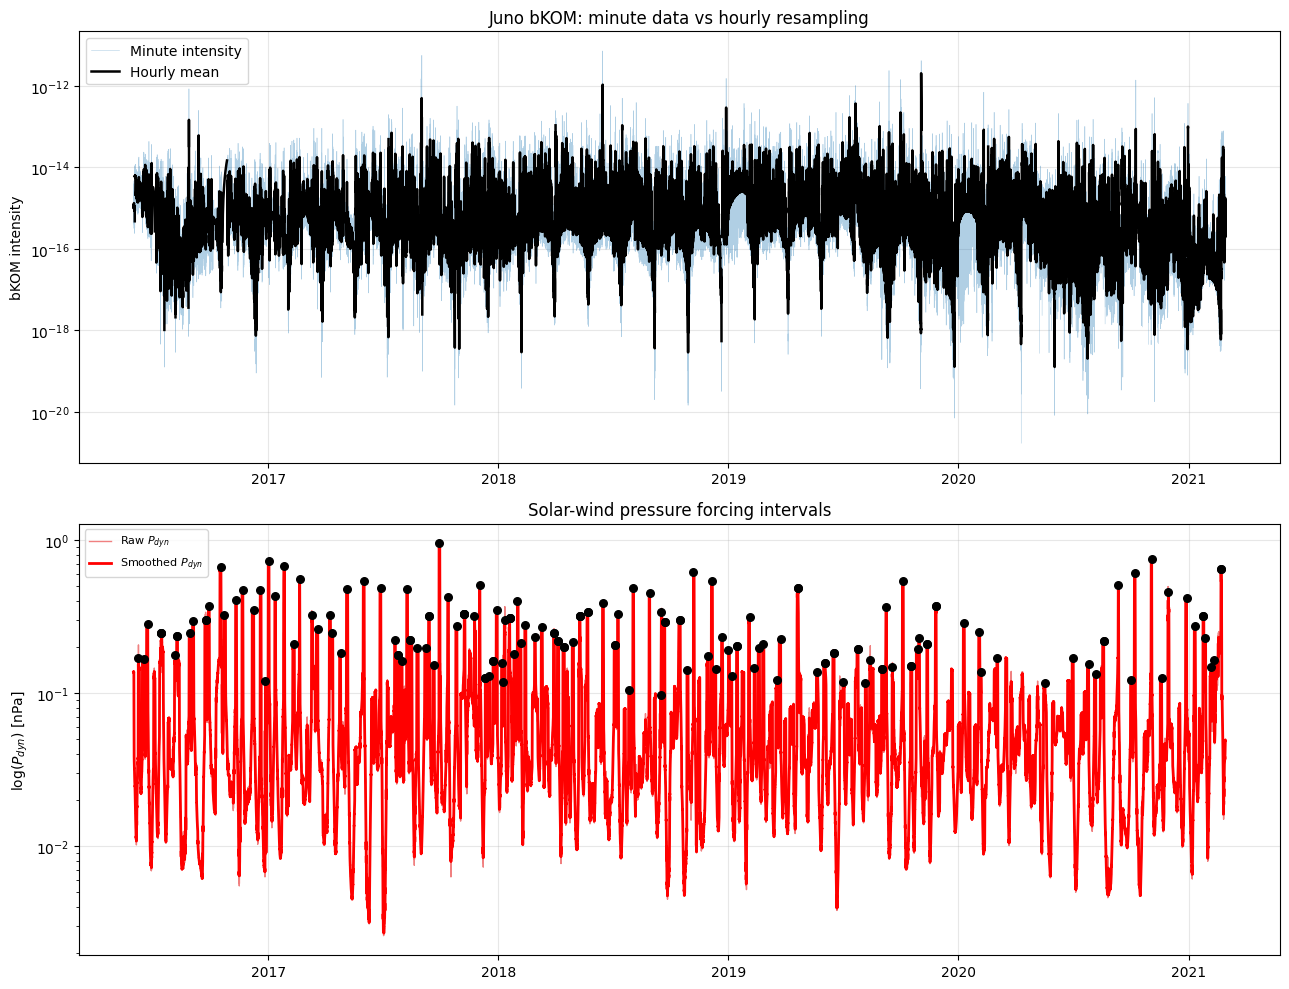

In [49]:
# =============================================================================
# PART D.1 — VISUAL CHECK
# =============================================================================

fig, ax = plt.subplots(2,1, figsize=(13, 10))

ax[0].plot(df_juno_min_subset.index, df_juno_min_subset["intensity"], lw=0.4, alpha=0.35, label="Minute intensity")
ax[0].plot(df_hourly1.index, df_hourly1["intensity"], lw=1.8, color="black", label="Hourly mean")

ax[0].set_yscale("log")
ax[0].set_ylabel("bKOM intensity")
ax[0].set_title("Juno bKOM: minute data vs hourly resampling")
ax[0].legend()
ax[0].grid(alpha=0.3)

ax[1].plot(P_dyn.index, P_dyn, color="lightcoral", lw=1, label="Raw $P_{dyn}$")
ax[1].plot(P_smooth.index, P_smooth, color="red", lw=2, label="Smoothed $P_{dyn}$")

for t_mid, row in df_forcing.iterrows():

    #ax.axvspan(row["forcing_start"], row["forcing_plateau_end"], color="red", alpha=0.08)
    #ax.axvline(row["forcing_start"], color="green", linestyle="--", lw=1)
    #ax.axvline(row["forcing_rise_end"], color="orange", linestyle="--", lw=1)
    #ax.axvline(row["forcing_plateau_end"], color="purple", linestyle="--", lw=1)
    ax[1].scatter(row["forcing_peak_time"], row["forcing_peak_value"], color="black", s=30, zorder=5)

ax[1].set_ylabel(r"log($P_{dyn}$) [nPa]")
ax[1].set_title("Solar-wind pressure forcing intervals")
ax[1].grid(alpha=0.3)
ax[1].legend(fontsize=8)
ax[1].set_yscale('log')
plt.tight_layout()
plt.savefig("dataset.pdf")
plt.show()


In [52]:
df_hourly1

,intensity,dist
time,,
2016-06-01 00:00:00,1.140641e-15,317.984757
2016-06-01 01:00:00,1.077881e-15,317.668095
2016-06-01 02:00:00,1.131956e-15,317.350042
2016-06-01 03:00:00,1.124121e-15,317.032099
2016-06-01 04:00:00,1.205322e-15,316.714076
...,...,...
2021-02-27 18:00:00,1.337318e-15,63.563264
2021-02-27 19:00:00,1.011716e-15,63.808300
2021-02-27 20:00:00,3.413475e-16,64.052330


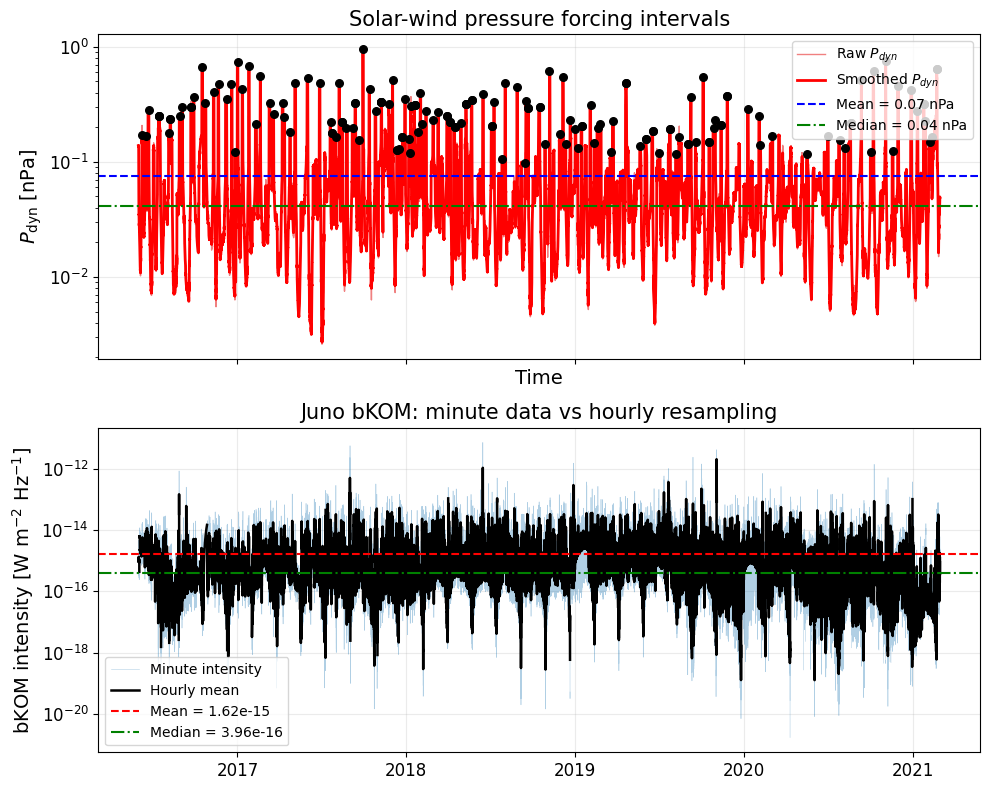

In [87]:
# Global statistics
bkom_mean = df_hourly1["intensity"].mean()
bkom_median = df_hourly1["intensity"].median()

P_mean = P_dyn.mean()
P_median = P_dyn.median()

fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# ---------------- bKOM ----------------
ax[1].plot(df_juno_min_subset.index, df_juno_min_subset["intensity"],
           lw=0.4, alpha=0.35, label="Minute intensity")
ax[1].plot(df_hourly1.index, df_hourly1["intensity"],
           lw=1.8, color="black", label="Hourly mean")

ax[1].axhline(bkom_mean, color="red", ls="--", lw=1.5,
              label=f"Mean = {bkom_mean:.2e}")
ax[1].axhline(bkom_median, color="green", ls="-.", lw=1.5,
              label=f"Median = {bkom_median:.2e}")

ax[1].set_yscale("log")
ax[1].set_ylabel(r"bKOM intensity [W m$^{-2}$ Hz$^{-1}$]", fontsize=14)
ax[1].set_title("Juno bKOM: minute data vs hourly resampling", fontsize=15)
ax[1].tick_params(labelsize=12)
ax[1].legend(fontsize=10)
ax[1].grid(alpha=0.25)


# ---------------- P_dyn ----------------
ax[0].plot(P_dyn.index, P_dyn, color="lightcoral", lw=1,
           label="Raw $P_{dyn}$")
ax[0].plot(P_smooth.index, P_smooth, color="red", lw=2,
           label="Smoothed $P_{dyn}$")

for t_mid, row in df_forcing.iterrows():
    ax[0].scatter(row["forcing_peak_time"], row["forcing_peak_value"],
                  color="black", s=30, zorder=5)

ax[0].axhline(P_mean, color="blue", ls="--", lw=1.5,
              label=f"Mean = {P_mean:.2f} nPa")
ax[0].axhline(P_median, color="green", ls="-.", lw=1.5,
              label=f"Median = {P_median:.2f} nPa")

ax[0].set_yscale("log")
ax[0].set_ylabel(r"$P_{\rm dyn}$ [nPa]", fontsize=14)
ax[0].set_xlabel("Time", fontsize=14)
ax[0].set_title("Solar-wind pressure forcing intervals", fontsize=15)
ax[0].tick_params(labelsize=12)
ax[0].legend(fontsize=10)
ax[0].grid(alpha=0.25)

plt.tight_layout()
plt.savefig("plots_rep/dataset.pdf", bbox_inches="tight")
plt.show()

In [77]:
SMOOTH_B = 3
SMOOTH_N = 3

In [78]:
# =============================================================================
# PART C-B — DETECT MAGNETIC FIELD FORCING INTERVALS
# =============================================================================

B_smooth = B_mag.rolling(SMOOTH_B, center=True, min_periods=1).mean()

dB = B_smooth.diff()

# Statistically defined threshold:
# strongest 5% of positive hourly increases
positive_dB = dB[dB > 0].dropna()

B_DERIV_THRESHOLD = positive_dB.quantile(0.95)

rising = dB > B_DERIV_THRESHOLD

forcing_records_B = []

in_forcing = False
forcing_start = None

for t in rising.index:

    if rising.loc[t] and not in_forcing:
        in_forcing = True
        forcing_start = t

    elif (not rising.loc[t]) and in_forcing:

        forcing_rise_end = t

        forcing_rise_duration_hr = (
            forcing_rise_end - forcing_start
        ).total_seconds() / 3600

        if forcing_rise_duration_hr >= MIN_EVENT_DURATION:

            rise_end_value = B_smooth.asof(forcing_rise_end)
            plateau_threshold = PLATEAU_FRACTION * rise_end_value

            after_rise = B_smooth.loc[forcing_rise_end:]
            forcing_plateau_end = after_rise.index[-1]

            for tt, val in after_rise.items():
                if val < plateau_threshold:
                    forcing_plateau_end = tt
                    break

            forcing_window = B_smooth.loc[
                forcing_start:forcing_plateau_end
            ]

            forcing_peak_time = forcing_window.idxmax()
            forcing_peak_value = forcing_window.max()

            forcing_midpoint = (
                forcing_start +
                (forcing_rise_end - forcing_start)/2
            )

            forcing_plateau_duration_hr = (
                forcing_plateau_end - forcing_rise_end
            ).total_seconds()/3600

            forcing_duration_hr = (
                forcing_plateau_end - forcing_start
            ).total_seconds()/3600

            forcing_records_B.append({

                "forcing_start": forcing_start,
                "forcing_rise_end": forcing_rise_end,
                "forcing_peak_value": forcing_peak_value,
                "forcing_plateau_end": forcing_plateau_end,
                "forcing_midpoint": forcing_midpoint,
                "forcing_peak_time": forcing_peak_time,

                "forcing_rise_duration_hr": forcing_rise_duration_hr,
                "forcing_plateau_duration_hr": forcing_plateau_duration_hr,
                "forcing_duration_hr_B": forcing_duration_hr,

                #"plateau_threshold": plateau_threshold,
                #"rise_end_value": rise_end_value,
            })

        in_forcing = False

df_forcing = pd.DataFrame(forcing_records_B)

if not df_forcing.empty:
    df_forcing = df_forcing.set_index("forcing_midpoint")

print(df_forcing.shape)

(125, 8)


In [86]:
# =============================================================================
# PART C-N — DETECT DENSITY FORCING INTERVALS
# =============================================================================

N_smooth = n_tot.rolling(SMOOTH_N, center=True, min_periods=1).mean()
dN = N_smooth.diff()

# Statistically defined threshold:
# strongest 5% of positive hourly increases
positive_dN = dN[dN > 0].dropna()

N_DERIV_THRESHOLD = positive_dN.quantile(0.95)

rising = dN > N_DERIV_THRESHOLD

forcing_records_N = []

in_forcing = False
forcing_start = None

for t in rising.index:

    if rising.loc[t] and not in_forcing:
        in_forcing = True
        forcing_start = t

    elif (not rising.loc[t]) and in_forcing:

        forcing_rise_end = t

        forcing_rise_duration_hr = (
            forcing_rise_end - forcing_start
        ).total_seconds()/3600

        if forcing_rise_duration_hr >= MIN_EVENT_DURATION:

            rise_end_value = N_smooth.asof(forcing_rise_end)
            plateau_threshold = PLATEAU_FRACTION * rise_end_value

            after_rise = N_smooth.loc[forcing_rise_end:]
            forcing_plateau_end = after_rise.index[-1]

            for tt, val in after_rise.items():
                if val < plateau_threshold:
                    forcing_plateau_end = tt
                    break

            forcing_window = N_smooth.loc[
                forcing_start:forcing_plateau_end
            ]

            forcing_peak_time = forcing_window.idxmax()
            forcing_peak_value = forcing_window.max()

            forcing_midpoint = (
                forcing_start +
                (forcing_rise_end - forcing_start)/2
            )

            forcing_plateau_duration_hr = (
                forcing_plateau_end - forcing_rise_end
            ).total_seconds()/3600

            forcing_duration_hr = (
                forcing_plateau_end - forcing_start
            ).total_seconds()/3600

            forcing_records_N.append({

                "forcing_start": forcing_start,
                "forcing_rise_end": forcing_rise_end,
                "forcing_midpoint": forcing_midpoint,
                "forcing_peak_time": forcing_peak_time,
                "forcing_peak_value": forcing_peak_value,
                "forcing_plateau_end": forcing_plateau_end,

                "forcing_rise_duration_hr": forcing_rise_duration_hr,
                "forcing_plateau_duration_hr": forcing_plateau_duration_hr,
                "forcing_duration_hr": forcing_duration_hr,

                #"plateau_threshold": plateau_threshold,
                #"rise_end_value": rise_end_value,
            })

        in_forcing = False

df_forcing = pd.DataFrame(forcing_records_N)

if not df_forcing.empty:
    df_forcing = df_forcing.set_index("forcing_midpoint")

print(df_forcing.shape)

(171, 8)


(D) Finding the response, lag and active duration 

In [65]:
# =============================================================================
# D. FIND bKOM RESPONSE + GAUSSIAN ENVELOPE ACTIVE DURATION
# =============================================================================

from scipy.optimize import curve_fit
from scipy.signal import find_peaks

# -----------------------------------------------------------------------------
# Parameters
# -----------------------------------------------------------------------------

ENVELOPE_WINDOW = 20
ENVELOPE_QUANTILE = 0.90

FIT_WINDOW_BEFORE = 70
FIT_WINDOW_AFTER  = 70
MAX_ACTIVE_DURATION_HR = FIT_WINDOW_BEFORE + FIT_WINDOW_AFTER
MAX_SIGMA_HR = MAX_ACTIVE_DURATION_HR / 4

MIN_FIT_POINTS = 15

T0_BOUND = 36   # Gaussian centre allowed within ±36 h of burst peak
PEAK_PROMINENCE = 0.08

# -----------------------------------------------------------------------------
# Gaussian model
# -----------------------------------------------------------------------------

def gaussian_pulse(t, baseline, amp, t0, sigma_t):
    return baseline + amp * np.exp(-0.5 * ((t - t0) / sigma_t)**2)


# -----------------------------------------------------------------------------
# Main loop
# -----------------------------------------------------------------------------

bkom_results = []
used_response_times = []

for t_forcing, forcing_row in df_forcing.iterrows():

    # =========================================================================
    # LAYER 1: FIND bKOM BURST WITHIN ± BKOM_SEARCH_WINDOW
    # =========================================================================

    response_window = df_hourly.loc[
        t_forcing - pd.Timedelta(hours=BKOM_SEARCH_WINDOW):
        t_forcing + pd.Timedelta(hours=BKOM_SEARCH_WINDOW),
        "intensity"
    ].dropna()

    if len(response_window) < 5:
        continue

    logI_response = np.log10(response_window[response_window > 0]).dropna()

    if len(logI_response) < 5:
        continue

    dlogI = logI_response.diff()
    rising = dlogI > 0

    segments = []
    current_segment = []

    for t in rising.index:

        if rising.loc[t]:
            current_segment.append(t)

        else:
            if len(current_segment) > 1:
                segments.append(current_segment)
            current_segment = []

    if len(current_segment) > 1:
        segments.append(current_segment)

    if len(segments) == 0:
        continue

    # choose strongest log jump
    best_jump = -np.inf
    best_segment = None

    for seg in segments:

        t_start = seg[0]
        t_end   = seg[-1]

        jump = logI_response.loc[t_end] - logI_response.loc[t_start]

        if jump > best_jump:
            best_jump = jump
            best_segment = (t_start, t_end)

    burst_base, burst_peak = best_segment

    baseline_log = logI_response.loc[burst_base]
    peak_log     = logI_response.loc[burst_peak]

    jump_log = peak_log - baseline_log
    response_ratio = 10**jump_log

    burst_midpoint = burst_base + (burst_peak - burst_base) / 2

    burst_duration_hr = (
        burst_peak - burst_base
    ).total_seconds() / 3600

    # avoid assigning same burst to nearby forcing events
    if any(
        abs((burst_midpoint - used).total_seconds() / 3600) < 6
        for used in used_response_times
    ):
        continue

    used_response_times.append(burst_midpoint)

    # Correct lag definitions
    lag_hours_peak = (
        burst_peak - forcing_row["forcing_rise_end"]
    ).total_seconds() / 3600

    lag_hours_onset = (
        burst_base - forcing_row["forcing_start"]
    ).total_seconds() / 3600

    lag_hours_midpoints = (
        burst_midpoint - t_forcing
    ).total_seconds() / 3600

    # =========================================================================
    # LAYER 2: GAUSSIAN FIT TO ROLLING UPPER ENVELOPE
    # =========================================================================

    fit_window = df_hourly.loc[
        burst_peak - pd.Timedelta(hours=FIT_WINDOW_BEFORE):
        burst_peak + pd.Timedelta(hours=FIT_WINDOW_AFTER),
        "intensity"
    ].dropna()

    logI_fit = np.log10(fit_window[fit_window > 0]).dropna()

    if len(logI_fit) < MIN_FIT_POINTS:

        fit_success = False

        active_start = burst_base
        active_end = burst_peak
        active_duration_hr = burst_duration_hr

        fit_baseline = np.nan
        fit_amp = np.nan
        fit_t0 = np.nan
        fit_sigma_hr = np.nan
        energy_proxy = np.nan

    else:

        envelope = (logI_fit.rolling(ENVELOPE_WINDOW, center=True, min_periods=1).quantile(ENVELOPE_QUANTILE))

        t_hours = (envelope.index - burst_peak).total_seconds() / 3600

        y = envelope.values

        baseline_guess = np.nanpercentile(y, 20)
        amp_guess = np.nanmax(y) - baseline_guess

        if amp_guess <= 0:
            amp_guess = 0.1

        t0_guess = t_hours[np.nanargmax(y)]
        sigma_guess = 18.0

        p0 = [baseline_guess, amp_guess, t0_guess, sigma_guess]

        bounds = ([np.nanmin(y) - 1.0, 0.0, -T0_BOUND, 2.0],[np.nanmax(y) + 1.0, 5.0, T0_BOUND, MAX_SIGMA_HR])

        try:
            popt, pcov = curve_fit(gaussian_pulse, t_hours, y, p0=p0, bounds=bounds, maxfev=20000)
            fit_baseline, fit_amp, fit_t0, fit_sigma_hr = popt

            # Main active-duration definition: ±2 sigma
            active_start = burst_peak + pd.Timedelta(hours=fit_t0 - 2 * fit_sigma_hr)
            active_end = burst_peak + pd.Timedelta(hours=fit_t0 + 2 * fit_sigma_hr)

            active_duration_hr = 4 * fit_sigma_hr

            # Integral of Gaussian excess above baseline in log-space units
            energy_proxy = fit_amp * fit_sigma_hr * np.sqrt(2 * np.pi)

            fit_success = True

        except Exception:

            fit_success = False

            active_start = burst_base
            active_end = burst_peak
            active_duration_hr = burst_duration_hr

            fit_baseline = np.nan
            fit_amp = np.nan
            fit_t0 = np.nan
            fit_sigma_hr = np.nan
            energy_proxy = np.nan

        active_logI = (np.log10(df_hourly.loc[active_start:active_end, "intensity"]).replace([np.inf, -np.inf],np.nan).dropna())
        if len(active_logI) < 3:
            n_peaks = np.nan
        else:
            peaks, _ = find_peaks(active_logI.values)

        n_peaks = len(peaks)

    # =========================================================================
    # Juno distance during active interval
    # =========================================================================

    dist_window = df_hourly.loc[active_start:active_end, "dist"].dropna()

    if len(dist_window) > 0:
        r_min_RJ = dist_window.min()
        r_max_RJ = dist_window.max()
        r_mean_RJ = dist_window.mean()
        r_std_RJ = dist_window.std()
    else:
        r_min_RJ = np.nan
        r_max_RJ = np.nan
        r_mean_RJ = np.nan
        r_std_RJ = np.nan

    # =========================================================================
    # STORE
    # =========================================================================

    bkom_results.append({
        "forcing_midpoint": t_forcing,

        # burst quantities
        "burst_base": burst_base,
        "burst_peak": burst_peak,
        "burst_midpoint": burst_midpoint,
        "burst_duration_hr": burst_duration_hr,

        # lag quantities
        "lag_hours_peak": lag_hours_peak,
        "lag_hours_onset": lag_hours_onset,
        "lag_hours_midpoints": lag_hours_midpoints,

        # response strength
        "baseline_log": baseline_log,
        "peak_log": peak_log,
        "jump_log": jump_log,
        "response_ratio": response_ratio,

        # active interval: ±2 sigma
        "active_start": active_start,
        "active_end": active_end,
        "active_duration_hr": active_duration_hr,

        # Gaussian fit
        "fit_success": fit_success,
        "fit_baseline_log": fit_baseline,
        "fit_amp_log": fit_amp,
        "fit_t0_hr": fit_t0,
        "fit_sigma_hr": fit_sigma_hr,
        "energy_proxy": energy_proxy,

        # Juno distance
        "r_min_RJ": r_min_RJ,
        "r_max_RJ": r_max_RJ,
        "r_mean_RJ": r_mean_RJ,
        "r_std_RJ": r_std_RJ,
        "n_peaks" : n_peaks,
    })


df_bkom = pd.DataFrame(bkom_results)

if not df_bkom.empty:
    df_bkom = df_bkom.set_index("forcing_midpoint")

#print(df_bkom)

Plotting pair #16
Forcing midpoint: 2016-12-06 05:30:00


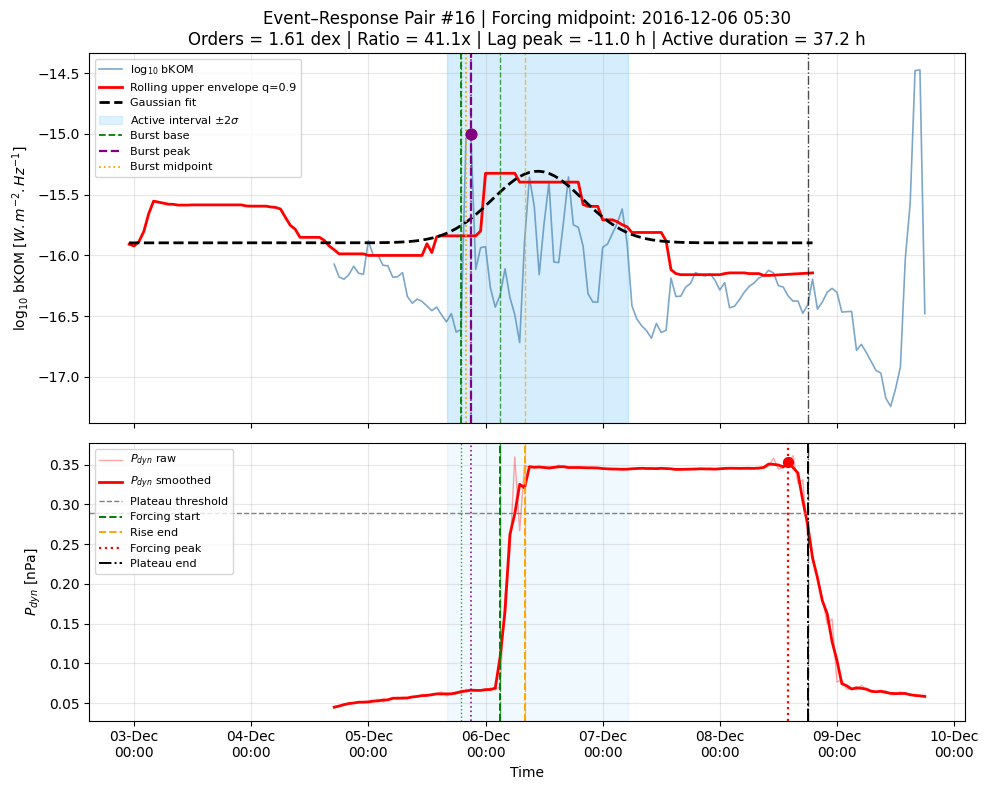

In [69]:
# =============================================================================
# EVENT–RESPONSE PAIR DIAGNOSTIC PLOT
# =============================================================================

import matplotlib.dates as mdates

# -----------------------------------------------------------------------------
# Choose event-response pair here
# -----------------------------------------------------------------------------

PAIR_NUMBER = 16   # 1, 2, 3, ...

# -----------------------------------------------------------------------------
# Build combined event-response table
# -----------------------------------------------------------------------------

df_pair_table = df_forcing.join(df_bkom, how="inner")

t_pair = df_pair_table.index[PAIR_NUMBER - 1]
row = df_pair_table.loc[t_pair]

print(f"Plotting pair #{PAIR_NUMBER}")
print("Forcing midpoint:", t_pair)

# -----------------------------------------------------------------------------
# Plot window
# -----------------------------------------------------------------------------

plot_start = min(row["forcing_start"], row["burst_base"], row["active_start"]) - pd.Timedelta(hours=24)
plot_end   = max(row["forcing_plateau_end"], row["burst_peak"], row["active_end"]) + pd.Timedelta(hours=24)

# -----------------------------------------------------------------------------
# Reconstruct bKOM log intensity, upper envelope, and Gaussian fit
# -----------------------------------------------------------------------------

i_plot = df_hourly.loc[plot_start:plot_end, "intensity"].dropna()
logI_plot = np.log10(i_plot[i_plot > 0]).dropna()

fit_window = df_hourly.loc[
    row["burst_peak"] - pd.Timedelta(hours=FIT_WINDOW_BEFORE):
    row["burst_peak"] + pd.Timedelta(hours=FIT_WINDOW_AFTER),
    "intensity"
].dropna()

logI_fit = np.log10(fit_window[fit_window > 0]).dropna()

envelope = (
    logI_fit
    .rolling(
        ENVELOPE_WINDOW,
        center=True,
        min_periods=1
    )
    .quantile(ENVELOPE_QUANTILE)
)

# Gaussian curve from saved fit parameters
if row["fit_success"]:

    t_hours_env = (
        envelope.index - row["burst_peak"]
    ).total_seconds() / 3600

    gauss_y = gaussian_pulse(
        t_hours_env,
        row["fit_baseline_log"],
        row["fit_amp_log"],
        row["fit_t0_hr"],
        row["fit_sigma_hr"]
    )

else:
    gauss_y = None

# -----------------------------------------------------------------------------
# Local MMESH/JSE slices
# -----------------------------------------------------------------------------

P_plot = P_dyn.loc[plot_start:plot_end]
P_smooth_plot = P_smooth.loc[plot_start:plot_end]

B_plot = B_mag.loc[plot_start:plot_end]
n_plot = n_tot.loc[plot_start:plot_end]
u_plot = u_mag.loc[plot_start:plot_end]

dist_plot = df_hourly.loc[plot_start:plot_end, "dist"]

if "df_jse" in globals():
    jse_plot = df_jse.loc[plot_start:plot_end, "angle"]
else:
    jse_plot = None

# -----------------------------------------------------------------------------
# Figure
# -----------------------------------------------------------------------------

n_panels = 2 if jse_plot is not None else 5

fig, axs = plt.subplots(
    n_panels, 1,
    figsize=(10, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [1.6, 1.2, 1, 1, 1, 1][:n_panels]}
)

# =============================================================================
# Panel 1: bKOM response + envelope + Gaussian fit
# =============================================================================

ax = axs[0]

ax.plot(
    logI_plot.index,
    logI_plot.values,
    color="steelblue",
    lw=1.2,
    alpha=0.7,
    label=r"log$_{10}$ bKOM"
)

ax.plot(
    envelope.index,
    envelope.values,
    color="red",
    lw=2,
    label=f"Rolling upper envelope q={ENVELOPE_QUANTILE}"
)

if gauss_y is not None:
    ax.plot(
        envelope.index,
        gauss_y,
        color="black",
        lw=2,
        linestyle="--",
        label="Gaussian fit"
    )

ax.axvspan(
    row["active_start"],
    row["active_end"],
    color="lightskyblue",
    alpha=0.25,
    label=r"Active interval $\pm 2\sigma$"
)

ax.axvline(row["burst_base"], color="green", linestyle="--", lw=1.3, label="Burst base")
ax.axvline(row["burst_peak"], color="purple", linestyle="--", lw=1.6, label="Burst peak")
ax.axvline(row["burst_midpoint"], color="orange", linestyle=":", lw=1.3, label="Burst midpoint")

ax.scatter(
    row["burst_peak"],
    row["peak_log"],
    color="purple",
    s=60,
    zorder=5
)

ax.set_ylabel(r"log$_{10}$ bKOM [$W. m^{-2} . Hz^{-1}$]")
ax.set_title(
    f"Event–Response Pair #{PAIR_NUMBER} | "
    f"Forcing midpoint: {t_pair.strftime('%Y-%m-%d %H:%M')}\n"
    f"Orders = {row['jump_log']:.2f} dex | "
    f"Ratio = {row['response_ratio']:.1f}x | "
    f"Lag peak = {row['lag_hours_peak']:.1f} h | "
    f"Active duration = {row['active_duration_hr']:.1f} h"
)
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.3)

# =============================================================================
# Panel 2: P_dyn forcing
# =============================================================================

ax = axs[1]

ax.plot(P_plot.index, P_plot.values, color="red", alpha=0.35, lw=1, label=r"$P_{dyn}$ raw")
ax.plot(P_smooth_plot.index, P_smooth_plot.values, color="red", lw=2, label=r"$P_{dyn}$ smoothed")

ax.axhline(
    row["plateau_threshold"],
    color="grey",
    linestyle="--",
    lw=1,
    label="Plateau threshold"
)

ax.axvline(row["forcing_start"], color="green", linestyle="--", lw=1.4, label="Forcing start")
ax.axvline(row["forcing_rise_end"], color="orange", linestyle="--", lw=1.4, label="Rise end")
ax.axvline(row["forcing_peak_time"], color="red", linestyle=":", lw=1.6, label="Forcing peak")
ax.axvline(row["forcing_plateau_end"], color="black", linestyle="-.", lw=1.4, label="Plateau end")

ax.scatter(
    row["forcing_peak_time"],
    row["forcing_peak_value"],
    color="red",
    s=50,
    zorder=5
)

ax.set_ylabel(r"$P_{dyn}$ [nPa]")
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.3)

# =============================================================================
# Panel 3: Distance
# =============================================================================
'''
ax = axs[2]

ax.plot(jse_plot.index, jse_plot.values, color="purple", lw=1.5)
ax.set_ylabel("JSE angle [deg]")
ax.set_ylim(-180, 180)
ax.grid(alpha=0.3)

#ax.plot(dist_plot.index, dist_plot.values, color="tab:blue", lw=1.5)
#ax.axhline(10, color="grey", linestyle="--", lw=1)

#ax.set_ylabel(r"Dist [$R_J$]")
#ax.grid(alpha=0.3)


# =============================================================================
# Panel 4: B_mag
# =============================================================================

ax = axs[3]

ax.plot(B_plot.index, B_plot.values, color="pink", lw=1.5)
ax.set_ylabel(r"$B_{mag}$ [nT]")
ax.grid(alpha=0.3)

# =============================================================================
# Panel 5: n_tot
# =============================================================================

ax = axs[4]

ax.plot(n_plot.index, n_plot.values, color="green", lw=1.5)
ax.set_ylabel(r"$n_{tot}$")
ax.grid(alpha=0.3)

# =============================================================================
# Panel 6: u_mag or JSE depending on availability
# =============================================================================

if jse_plot is None:

    ax = axs[5 - 1]

    ax.plot(u_plot.index, u_plot.values, color="black", lw=1.5)
    ax.set_ylabel(r"$u_{mag}$ [km/s]")
    ax.grid(alpha=0.3)

else:

    ax = axs[5]

    ax.plot(jse_plot.index, jse_plot.values, color="purple", lw=1.5)
    ax.set_ylabel("JSE angle [deg]")
    ax.set_ylim(-180, 180)
    ax.grid(alpha=0.3)

    # Add u_mag as panel 5? Replace n? No. Instead use twin axis on n panel.
    ax_u = axs[4].twinx()
    ax_u.plot(u_plot.index, u_plot.values, color="black", lw=1.2, alpha=0.7)
    ax_u.set_ylabel(r"$u_{mag}$ [km/s]", color="black")
    ax_u.tick_params(axis="y", labelcolor="black")
'''
# -----------------------------------------------------------------------------
# Shared vertical markers on all panels
# -----------------------------------------------------------------------------

for ax in axs:

    ax.axvline(row["forcing_start"], color="green", linestyle="--", lw=1, alpha=0.7)
    ax.axvline(row["forcing_rise_end"], color="orange", linestyle="--", lw=1, alpha=0.7)
    ax.axvline(row["forcing_plateau_end"], color="black", linestyle="-.", lw=1, alpha=0.7)

    ax.axvline(row["burst_base"], color="green", linestyle=":", lw=1, alpha=0.8)
    ax.axvline(row["burst_peak"], color="purple", linestyle=":", lw=1.2, alpha=0.9)

    ax.axvspan(
        row["active_start"],
        row["active_end"],
        color="lightskyblue",
        alpha=0.12
    )

# -----------------------------------------------------------------------------
# X-axis formatting
# -----------------------------------------------------------------------------

axs[-1].set_xlabel("Time")
axs[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b\n%H:%M"))

plt.tight_layout()
plt.savefig("methodology.pdf", bbox_inches="tight")
plt.show()


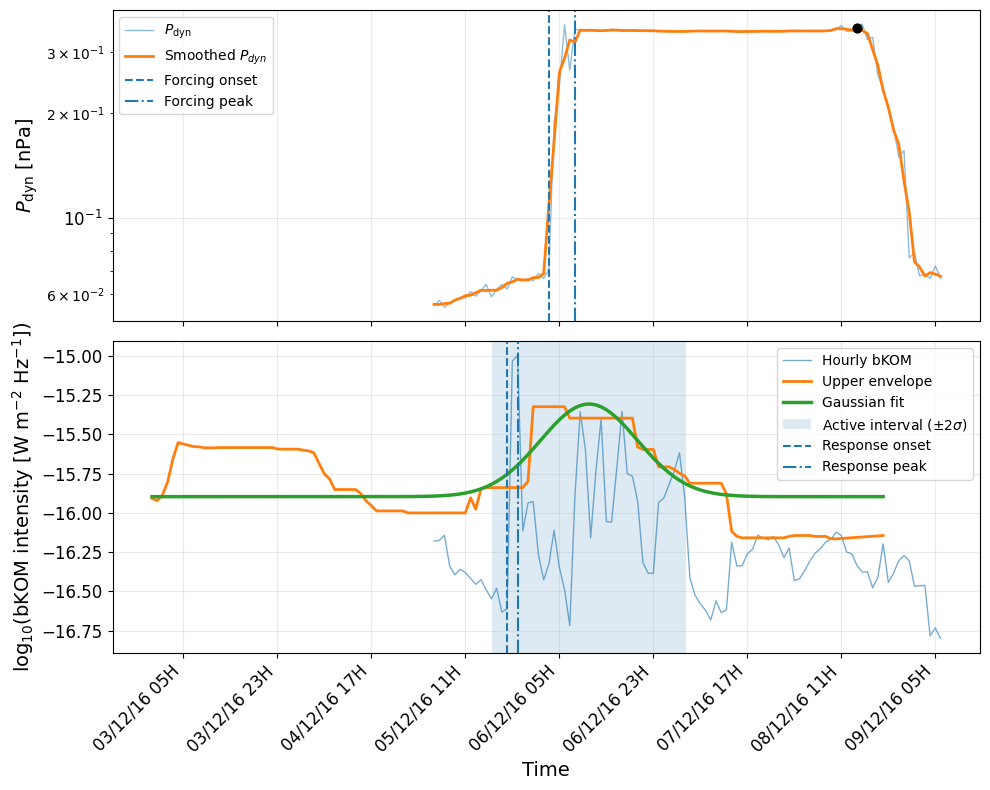

In [ ]:
import matplotlib.dates as mdates

event_no = 15

t_forcing = df_bkom.index[event_no]
b = df_bkom.iloc[event_no]
f = df_forcing.loc[t_forcing]

# Plotting window
t1 = min(f["forcing_start"], b["active_start"]) - pd.Timedelta(hours=12)
t2 = max(f["forcing_plateau_end"], b["active_end"]) + pd.Timedelta(hours=12)

fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# =============================================================================
# Solar-wind forcing
# =============================================================================

ax[0].plot(P_dyn.loc[t1:t2], lw=1, alpha=0.5, label=r"$P_{\rm dyn}$")
ax[0].plot(P_smooth.loc[t1:t2], lw=2, label="Smoothed $P_{dyn}$")

ax[0].axvline(f["forcing_start"], ls="--", lw=1.5, label="Forcing onset")
ax[0].axvline(f["forcing_rise_end"], ls="-.", lw=1.5, label="Forcing peak")

ax[0].scatter(f["forcing_peak_time"], f["forcing_peak_value"],
              color="black", s=40, zorder=5)

ax[0].set_yscale("log")
ax[0].set_ylabel(r"$P_{\rm dyn}$ [nPa]", fontsize=14)
ax[0].tick_params(labelsize=12)
ax[0].legend(fontsize=10)
ax[0].grid(alpha=0.25)


# =============================================================================
# bKOM response + Gaussian envelope
# =============================================================================

response = df_hourly.loc[t1:t2, "intensity"].dropna()
log_response = np.log10(response[response > 0])

ax[1].plot(log_response.index, log_response,
           lw=1, alpha=0.6, label="Hourly bKOM")

# Reconstruct envelope
fit_window = df_hourly.loc[
    b["burst_peak"] - pd.Timedelta(hours=FIT_WINDOW_BEFORE):
    b["burst_peak"] + pd.Timedelta(hours=FIT_WINDOW_AFTER),
    "intensity"
].dropna()

logI_fit = np.log10(fit_window[fit_window > 0])

envelope = logI_fit.rolling(
    ENVELOPE_WINDOW,
    center=True,
    min_periods=1
).quantile(ENVELOPE_QUANTILE)

ax[1].plot(envelope.index, envelope, lw=2, label="Upper envelope")


# Gaussian fit
if b["fit_success"]:

    t_hours = (envelope.index - b["burst_peak"]).total_seconds() / 3600

    gaussian_fit = gaussian_pulse(
        t_hours,
        b["fit_baseline_log"],
        b["fit_amp_log"],
        b["fit_t0_hr"],
        b["fit_sigma_hr"]
    )

    ax[1].plot(envelope.index, gaussian_fit,
               lw=2.5, label="Gaussian fit")

    ax[1].axvspan(
        b["active_start"], b["active_end"],
        alpha=0.15,
        label=r"Active interval ($\pm2\sigma$)"
    )


ax[1].axvline(b["burst_base"], ls="--", lw=1.5,
              label="Response onset")

ax[1].axvline(b["burst_peak"], ls="-.", lw=1.5,
              label="Response peak")

ax[1].set_ylabel(
    r"log$_{10}$(bKOM intensity [W m$^{-2}$ Hz$^{-1}$])",
    fontsize=14
)
ax[1].set_xlabel("Time", fontsize=14)
ax[1].tick_params(labelsize=12)
ax[1].legend(fontsize=10)
ax[1].grid(alpha=0.25)


# =============================================================================
# Better time-axis formatting
# =============================================================================

locator = mdates.AutoDateLocator(minticks=5, maxticks=8)

ax[1].xaxis.set_major_locator(mdates.HourLocator(interval=18))
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y %HH"))

plt.setp(ax[1].get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.savefig("plots_rep/methodology.pdf", bbox_inches="tight")
plt.show()

(E) Joining the bKOM and MMESH event-response pairs

In [88]:
# =============================================================================
# PART E — JOIN FORCING + BKOM RESPONSE
# =============================================================================

df_combined = df_forcing.join(df_bkom, how="inner")

(G) Introducing the JSO parameter to divide the study into local time sectors

In [3]:
file_jso = '/obs/kkesri/code/ephem/juno_jup_xyz_jso_2016_2025.txt'

df_jso = pd.read_csv(
    file_jso,
    comment="#",
    sep=r"\s+",
    names=["time", "x_jso", "y_jso", "z_jso"]
)

df_jso["time"] = pd.to_datetime(df_jso["time"])
df_jso = df_jso.set_index("time").sort_index()

In [5]:
# =============================================================================
# G. JSO LOCAL TIME + SECTOR CLASSIFICATION
# =============================================================================
import numpy as np
# Longitude in degrees from JSO X-Y plane
df_jso["longitude_deg"] = np.degrees(
    np.arctan2(df_jso["y_jso"], df_jso["x_jso"])
)

# Convert longitude to local time
# x > 0 = Sunward = 12 LT
# x < 0 = anti-Sunward = 00 LT
df_jso["local_time_hr"] = np.mod(
    12 + (df_jso["longitude_deg"] / 180.0) * 12,
    24
)

# Sector classification:
# midnight: 21–03
# dawn:      03–09
# noon:      09–15
# dusk:      15–21

def classify_lt_sector(lt):
    if (lt >= 21) or (lt < 3):
        return "midnight"
    elif 3 <= lt < 9:
        return "dawn"
    elif 9 <= lt < 15:
        return "noon"
    elif 15 <= lt < 21:
        return "dusk"
    else:
        return np.nan

df_jso["lt_sector"] = df_jso["local_time_hr"].apply(classify_lt_sector)

print(df_jso[["x_jso", "y_jso", "z_jso", "longitude_deg", "local_time_hr", "lt_sector"]].head())
print(df_jso["lt_sector"].value_counts())

                       x_jso    y_jso    z_jso  longitude_deg  local_time_hr  \
time                                                                           
2016-06-01 00:05:00  24.5882 -314.219  43.1244     -85.525620       6.298292   
2016-06-01 00:10:00  24.5847 -314.193  43.1216     -85.525886       6.298274   
2016-06-01 00:15:00  24.5812 -314.167  43.1188     -85.526152       6.298257   
2016-06-01 00:20:00  24.5776 -314.141  43.1160     -85.526435       6.298238   
2016-06-01 00:25:00  24.5741 -314.115  43.1133     -85.526701       6.298220   

                    lt_sector  
time                           
2016-06-01 00:05:00      dawn  
2016-06-01 00:10:00      dawn  
2016-06-01 00:15:00      dawn  
2016-06-01 00:20:00      dawn  
2016-06-01 00:25:00      dawn  
lt_sector
midnight    369487
dusk        360801
dawn        198069
noon         58868
Name: count, dtype: int64


In [6]:
df_combined["x_jso"] = df_jso["x_jso"].reindex(df_combined.index, method="nearest")
df_combined["y_jso"] = df_jso["y_jso"].reindex(df_combined.index, method="nearest")
df_combined["z_jso"] = df_jso["z_jso"].reindex(df_combined.index, method="nearest")
df_combined["local_time_hr"] = df_jso["local_time_hr"].reindex(df_combined.index, method="nearest")
df_combined["lt_sector"] = df_jso["lt_sector"].reindex(df_combined.index, method="nearest")

print(df_combined[["x_jso", "y_jso", "z_jso", "local_time_hr", "lt_sector"]])

NameError: name 'df_combined' is not defined

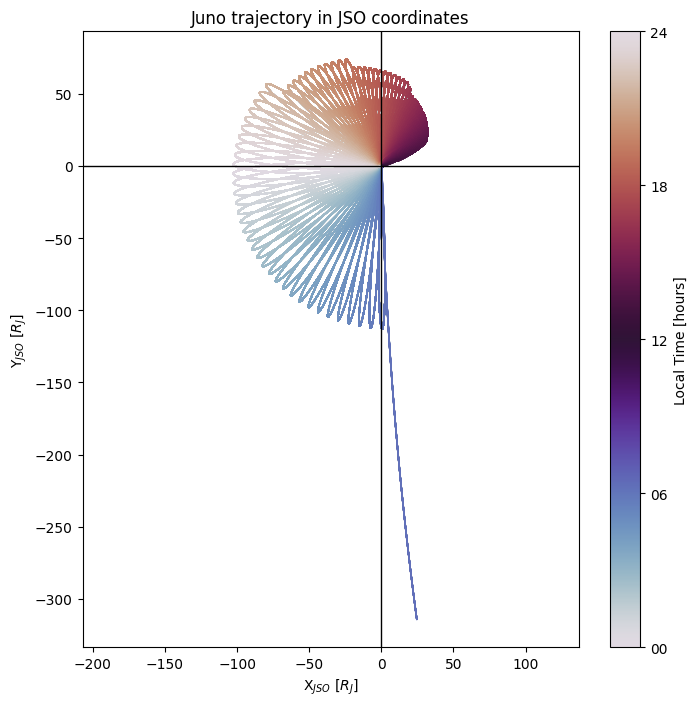

In [42]:
plt.figure(figsize=(8,8))

sc = plt.scatter(
    df_jso["x_jso"],
    df_jso["y_jso"],
    c=df_jso["local_time_hr"],
    s=0.01,
    cmap="twilight",
    vmin=0,
    vmax=24
)

plt.axhline(0, color="k", lw=1)
plt.axvline(0, color="k", lw=1)

plt.xlabel(r"X$_{JSO}$ [$R_J$]")
plt.ylabel(r"Y$_{JSO}$ [$R_J$]")
plt.title("Juno trajectory in JSO coordinates")

plt.axis("equal")

cbar = plt.colorbar(sc)
cbar.set_label("Local Time [hours]")
cbar.set_ticks([0, 6, 12, 18, 24])
cbar.set_ticklabels(["00", "06", "12", "18", "24"])

plt.show()

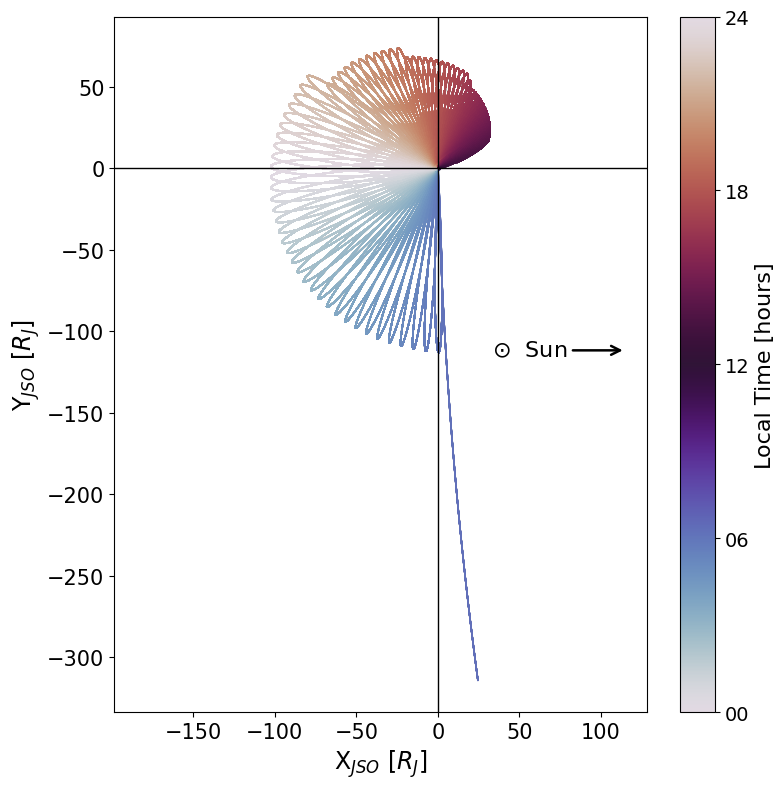

In [10]:
plt.figure(figsize=(8, 8))

sc = plt.scatter(
    df_jso["x_jso"],
    df_jso["y_jso"],
    c=df_jso["local_time_hr"],
    s=0.01,
    cmap="twilight",
    vmin=0,
    vmax=24,
    rasterized=True
)

plt.axhline(0, color="k", lw=1)
plt.axvline(0, color="k", lw=1)

# Sunward direction (+X_JSO)
ax = plt.gca()

ax.annotate(
    r"$\odot$  Sun",
    xy=(0.96, 0.52),
    xytext=(0.78, 0.52),
    xycoords="axes fraction",
    textcoords="axes fraction",
    fontsize=16,
    ha="center",
    va="center",
    arrowprops=dict(
        arrowstyle="->",
        lw=1.8,
        color="k"
    )
)

plt.xlabel(r"X$_{JSO}$ [$R_J$]", fontsize=17)
plt.ylabel(r"Y$_{JSO}$ [$R_J$]", fontsize=17)

plt.xticks(fontsize=15)
plt.yticks(fontsize=15)

plt.axis("equal")

cbar = plt.colorbar(sc)
cbar.set_label("Local Time [hours]", fontsize=16)
cbar.set_ticks([0, 6, 12, 18, 24])
cbar.set_ticklabels(["00", "06", "12", "18", "24"])
cbar.ax.tick_params(labelsize=14)

plt.tight_layout()

plt.savefig(
    "plots_rep/juno_trajectory.pdf",
    bbox_inches="tight",
    dpi=300
)

plt.show()

(G) Representing the entire ensemble that we have so far

In [94]:
print("Saving results...")
# Machine-readable
df_combined.to_csv("df_final_results_N.csv", float_format='%.6f')
print("✓ Saved: df_final_results.csv (for reloading)")

Saving results...
✓ Saved: df_final_results.csv (for reloading)


(I) Shocks Classification into FRS/FFS

(J) Introduing the solar cycle